In [13]:
import math
import numpy as np
import matplotlib.pyplot  as plt
import random
%matplotlib inline

In [19]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data = data
        self.grad = 0.0
        self._backward = lambda:None
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data = {self.data})"

    def __add__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data + other.data, (self,other),'+')
        def _backward():
            self.grad += 1.0 *out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out

    def __radd__(self,other):
        return self+other
    def __mul__(self,other):
        other = other if isinstance(other,Value) else Value(other)
        out = Value(self.data * other.data, (self,other),'*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out
    
    def __pow__(self,other):
        assert isinstance(other,(int,float))
        out = Value(self.data**other,(self,),f'**{other}')
        def _backward():
            self.grad += (other*(self.data ** (other-1)))*out.grad
        out._backward = _backward
        return out

    def __rmul__(self,other):
        return self*other

    def __truediv__(self,other):
        return self * other**-1

    def __neg__(self):
        return self * -1
    
    def __sub__(self,other):
        return self + (-other)
        
    def tanh(self):
        x=self.data
        t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
        out = Value(t,(self, ),'tanh')
        def  _backward():
            self.grad += (1-t**2)*out.grad
        out._backward = _backward
        return out
    
    def exp(self):
        x = self.data
        out = Value(math.exp(x),(self, ),'exp')
        def _backward():
            self.grad += out.data * out.grad 
        out._backward = _backward
        return out
        
    def backward(self):
        
        topo=[]
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()





In [3]:
from graphviz import Digraph
def trace(root):
    nodes, edges=set(),set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child,v))
                build(child)
    build(root)
    return nodes,edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir':'LR'})
    nodes,edges=trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid,label="{%s | data %.4f | grad %.4f}"%(n.label,n.data,n.grad),shape='record')
        if n._op:
            dot.node(name=uid+n._op,label=n._op)
            dot.edge(uid+n._op,uid)
    for n1,n2 in edges:
        dot.edge(str(id(n1)),str(id(n2)) + n2._op)
    return dot


In [4]:
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
b = Value(6.8813735870195432,label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1+x2w2;x1w1x2w2.label = 'x1w1+x2w2'
n  = x1w1x2w2+b;n.label = 'n'
o = n.tanh();o.label='o'
o.backward()


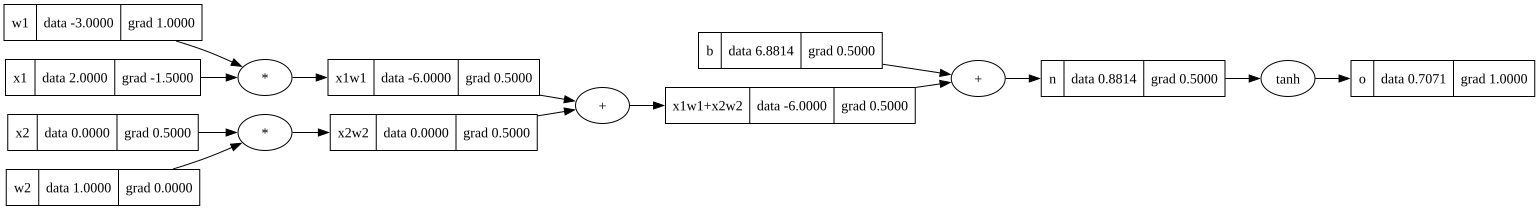

In [5]:
draw_dot(o)

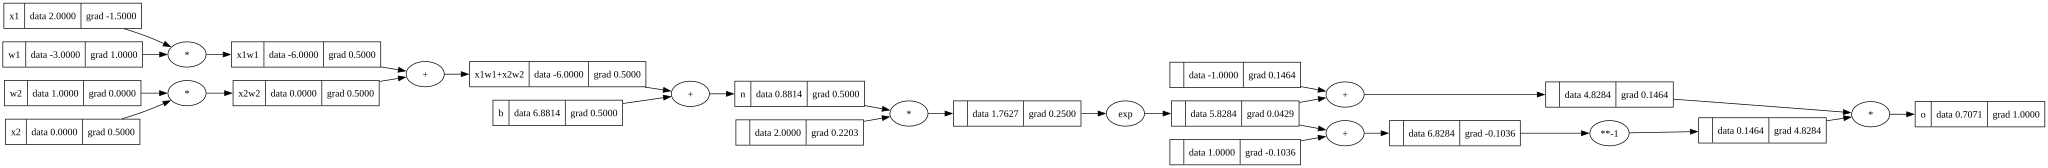

In [6]:
x1 = Value(2.0,label='x1')
x2 = Value(0.0,label='x2')
w1 = Value(-3.0,label='w1')
w2 = Value(1.0,label='w2')
b = Value(6.8813735870195432,label='b')
x1w1 = x1*w1; x1w1.label='x1w1'
x2w2 = x2*w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1+x2w2;x1w1x2w2.label = 'x1w1+x2w2'
n  = x1w1x2w2+b;n.label = 'n'
e = (2*n).exp()
o = (e-1)/(e+1)
o.label='o'
o.backward()
draw_dot(o)

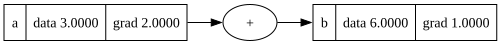

In [7]:
a = Value(3.0,label='a')
b = a+a;b.label='b'
b.backward()
draw_dot(b)

In [8]:
import torch

In [14]:
class Neuron:
    def __init__(self,nin):
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    def __call__(self,x):
        act = sum((wi*xi for wi,xi in zip(self.w,x)),self.b)
        out = act.tanh()
        return out
    def parameters(self):
        return self.w + [self.b]
class  Layer:
    def __init__(self,nin,nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def __call__(self,x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    def parameters(self):
        return  [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
    def __init__(self,nin,nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i],sz[i+1]) for i in range(len(nouts))]
    def __call__(self,x):
        for layer in self.layers:
            x = layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
x  = [2.0,3.0,-1.0]
n = MLP(3,[4,4,1])
n(x)

Value(data = -0.7090876191553479)

In [15]:
xs = [
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0],
]
ys = [1.0,-1.0,-1.0,1.0]
ypred = [n(x) for x in xs]
ypred

[Value(data = -0.7090876191553479),
 Value(data = -0.6988125416967801),
 Value(data = -0.7963882249132926),
 Value(data = -0.5694245848050277)]

In [ ]:
loss = sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))
loss

In [ ]:
loss.backward()

In [ ]:
n.layers[0].neurons[0].w[0].grad

In [ ]:
n,.layers[0].neurons[0].w[0].data

In [ ]:
for p in n.parameters():
    p.data += -0.01 * p.grad

In [20]:
for k in range(20):

    #forward pass
    ypred = [n(x) for x in xs]
    loss = sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))/len(ys)

    #backward pass
    for p in n.parameters():
        p.grad = 0.0
    loss.backward()

    #update
    for p in n.parameters():
        p.data += -0.05 * p.grad
    print(k,loss.data)

0 1.3790614143334108
1 1.241406259909873
2 1.0834750597613905
3 0.9291006027007045
4 0.808823637508815
5 0.7337617271239041
6 0.6916758683457227
7 0.6666378126843205
8 0.6489989512813024
9 0.6342332575833145
10 0.6203419873862371
11 0.6063956265310105
12 0.5918906018160368
13 0.5764833513393566
14 0.5598840636306478
15 0.5418203120952608
16 0.5220367901561324
17 0.500319653574372
18 0.47654028993073294
19 0.4507101707784708
